# 08 — Decomposição: tendência, sazonalidade e resíduo

Passo 6 do roteiro de EDA (`docs/02_roteiro_eda.md`): decompor `cambio_venda` e `exportação_fob` em **tendência**, **sazonalidade** e **resíduo**, para visualizar se dá para separar o efeito cambial do efeito sazonal do comércio.

**Perguntas do notebook:**

1. O modelo **aditivo** ou o **multiplicativo** descreve melhor cada série? (testamos os dois)
2. Quão forte é a sazonalidade no câmbio e nas exportações?
3. O choque cambial de 2020 aparece na tendência ou no resíduo?

**Escolhas metodológicas** (registradas aqui para o relatório):

- **Recorte:** painel completo, 132 meses (2015-01 a 2025-12), porque estas duas séries não usam colunas de crédito (decisão do `05_tratamento_nans.ipynb`). São 11 anos completos, então cada mês do calendário aparece exatamente 11 vezes.
- **Método:** decomposição clássica por médias móveis (`seasonal_decompose` do statsmodels), com **período = 12** (dados mensais).
- **Modelos:** aditivo (`série = tendência + sazonalidade + resíduo`, a sazonalidade soma um valor fixo) e multiplicativo (`série = tendência × sazonalidade × resíduo`, a sazonalidade é uma porcentagem do nível).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import seasonal_decompose

painel = pd.read_csv('https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/data/processed/painel_2015_2025.csv')
painel['data'] = pd.to_datetime(painel['ano'].astype(str) + '-' + painel['mes'].astype(str) + '-01')

series = ['cambio_venda', 'exportação_fob']
dados = painel.set_index('data')[series]
print(f"painel completo: {len(dados)} meses, NaNs nas séries usadas: {dados.isna().sum().sum()}")

def fmt(x, casas=2):
    """Número no formato brasileiro (vírgula decimal)."""
    return f"{x:.{casas}f}".replace('.', ',')

def tabela_md(df):
    """DataFrame de strings -> tabela Markdown."""
    cab = '| ' + ' | '.join([df.index.name or 'série'] + list(df.columns)) + ' |'
    sep = '|' + '---|' * (len(df.columns) + 1)
    linhas = ['| ' + ' | '.join([str(idx)] + [str(v) for v in row]) + ' |' for idx, row in df.iterrows()]
    return '\n'.join([cab, sep] + linhas)

MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']

decomp = {(c, m): seasonal_decompose(dados[c], model=m, period=12)
          for c in series for m in ['additive', 'multiplicative']}

painel completo: 132 meses, NaNs nas séries usadas: 0


## 1. Aditivo ou multiplicativo?

Dois critérios, ambos calculados sobre o **resíduo** (o que sobra depois de tirar tendência e sazonalidade; quanto menor e mais estável, melhor a decomposição):

- **Tamanho relativo do resíduo:** raiz da média dos quadrados do resíduo, medido como fração da tendência (no aditivo, `resíduo / tendência`; no multiplicativo, `resíduo − 1`, já que ele gira em torno de 1). Mesma unidade nos dois modelos, então dá para comparar.
- **Estabilidade:** desvio padrão do resíduo na 2ª metade da série dividido pelo da 1ª metade. Perto de 1 = resíduo com o mesmo tamanho ao longo do tempo. Bem acima de 1 = o resíduo cresce junto com o nível da série, sinal de que o modelo aditivo não está acompanhando a escala.

**Regra de decisão:** vence o modelo de menor resíduo relativo; se a diferença for menor que 0,0005 (empate prático), vence o de resíduo mais estável (razão mais próxima de 1).

In [2]:
def metricas(c, m):
    r = decomp[(c, m)]
    res = r.resid.dropna()
    tend = r.trend.loc[res.index]
    rel = res / tend if m == 'additive' else res - 1
    metade = len(res) // 2
    return {
        'rel': np.sqrt((rel ** 2).mean()),
        'estab': res.iloc[metade:].std() / res.iloc[:metade].std(),
    }

escolhido = {}
linhas = []
for c in series:
    ma, mm = metricas(c, 'additive'), metricas(c, 'multiplicative')
    if abs(ma['rel'] - mm['rel']) < 0.0005:
        escolhido[c] = 'additive' if abs(ma['estab'] - 1) <= abs(mm['estab'] - 1) else 'multiplicative'
        criterio = 'desempate por estabilidade'
    else:
        escolhido[c] = 'additive' if ma['rel'] < mm['rel'] else 'multiplicative'
        criterio = 'menor resíduo relativo'
    for m, mt in [('additive', ma), ('multiplicative', mm)]:
        linhas.append(f"| `{c}` | {'aditivo' if m == 'additive' else 'multiplicativo'} | {fmt(mt['rel'], 4)} | {fmt(mt['estab'])} | "
                      f"{'**escolhido** (' + criterio + ')' if escolhido[c] == m else ''} |")

display(Markdown('| série | modelo | resíduo relativo | estabilidade (2ª/1ª metade) | decisão |\n|---|---|---|---|---|\n' + '\n'.join(linhas)))

| série | modelo | resíduo relativo | estabilidade (2ª/1ª metade) | decisão |
|---|---|---|---|---|
| `cambio_venda` | aditivo | 0,0412 | 1,01 | **escolhido** (desempate por estabilidade) |
| `cambio_venda` | multiplicativo | 0,0412 | 0,78 |  |
| `exportação_fob` | aditivo | 0,0814 | 1,35 |  |
| `exportação_fob` | multiplicativo | 0,0790 | 0,96 | **escolhido** (menor resíduo relativo) |

## 2. As componentes, com o modelo escolhido

Cada coluna mostra uma série: **observado**, **tendência** (média móvel centrada de 12 meses), **sazonalidade** (padrão que se repete a cada ano, igual em todos os anos) e **resíduo** (o que sobrou). A tendência e o resíduo ficam sem valor nos 6 primeiros e 6 últimos meses, porque a média móvel centrada precisa de meses dos dois lados.

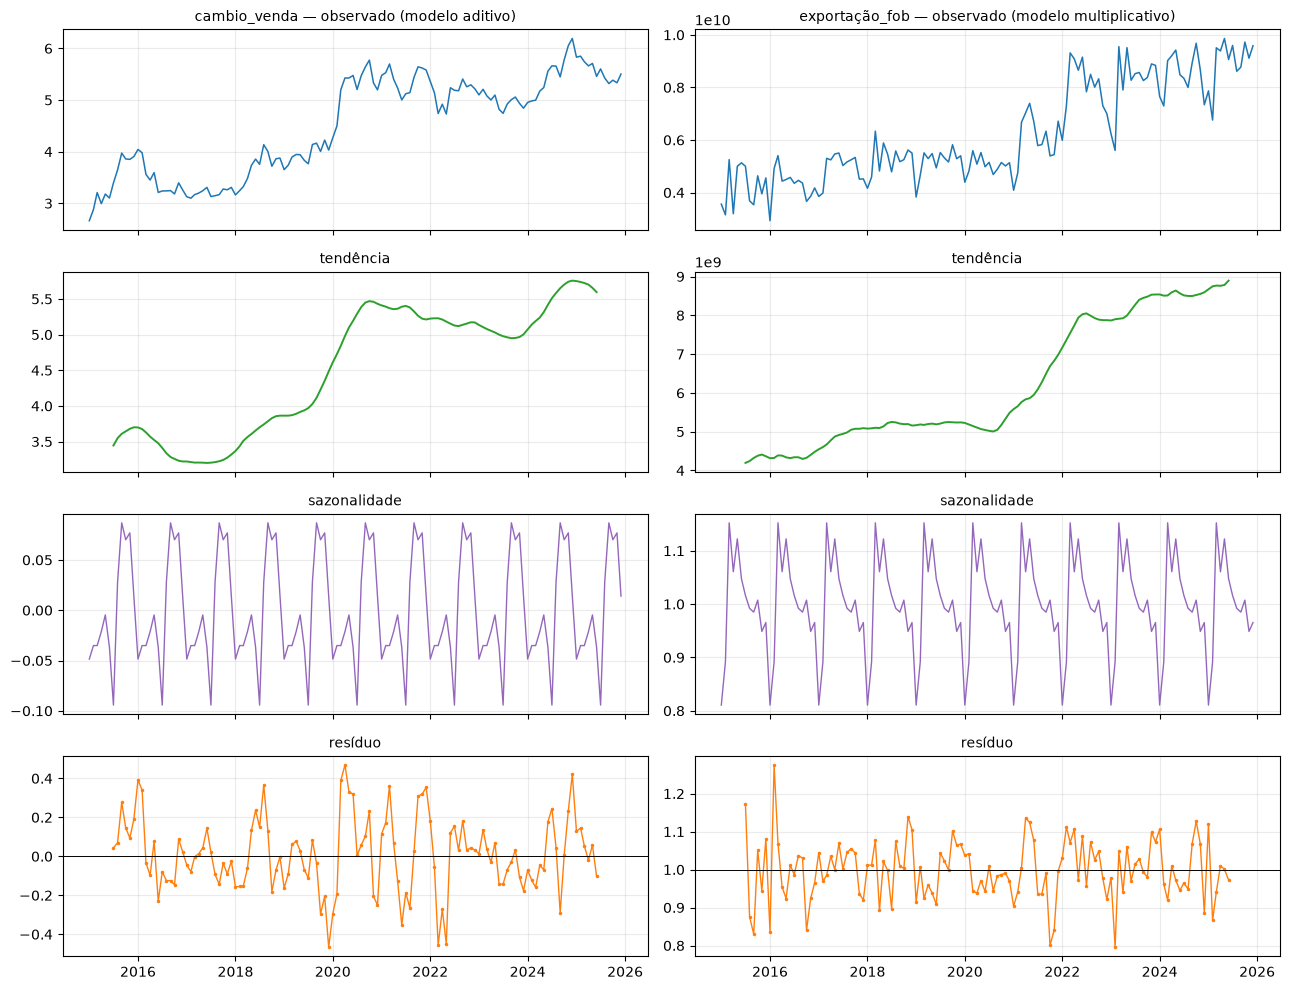

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(13, 10), sharex='col')
for j, c in enumerate(series):
    m = escolhido[c]
    r = decomp[(c, m)]
    nome_m = 'aditivo' if m == 'additive' else 'multiplicativo'
    axes[0, j].plot(r.observed, color='tab:blue', linewidth=1.1)
    axes[0, j].set_title(f'{c} — observado (modelo {nome_m})', fontsize=10)
    axes[1, j].plot(r.trend, color='tab:green', linewidth=1.4)
    axes[1, j].set_title('tendência', fontsize=10)
    axes[2, j].plot(r.seasonal, color='tab:purple', linewidth=1.0)
    axes[2, j].set_title('sazonalidade', fontsize=10)
    axes[3, j].plot(r.resid, color='tab:orange', linewidth=1.0, marker='.', markersize=3)
    axes[3, j].axhline(0 if m == 'additive' else 1, color='black', linewidth=0.7)
    axes[3, j].set_title('resíduo', fontsize=10)
    for ax in axes[:, j]:
        ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Quão forte é a tendência e quão forte é a sazonalidade?

Medida padrão (Hyndman & Athanasopoulos): **força** = `1 − Var(resíduo) / Var(componente + resíduo)`, entre 0 e 1.

- **Força da sazonalidade** perto de **0**: o padrão anual explica quase nada; perto de **1**: explica quase tudo o que sobra depois de tirar a tendência.
- **Força da tendência**: idem, para a tendência.

No modelo multiplicativo, a conta é feita nos logaritmos das componentes (o log transforma o produto em soma).

In [5]:
def forca(c):
    m = escolhido[c]
    r = decomp[(c, m)]
    T, S, R = r.trend.dropna(), r.seasonal, r.resid.dropna()
    S, T = S.loc[R.index], T.loc[R.index]
    if m == 'multiplicative':
        T, S, R = np.log(T), np.log(S), np.log(R)
    return {'tendência': max(0, 1 - R.var() / (T + R).var()),
            'sazonalidade': max(0, 1 - R.var() / (S + R).var())}

fs = {c: forca(c) for c in series}
tab = pd.DataFrame({c: {k: fmt(v) for k, v in fs[c].items()} for c in series}).T
tab.index.name = 'série'
display(Markdown(tabela_md(tab.rename(columns={'tendência': 'força da tendência', 'sazonalidade': 'força da sazonalidade'}))))

def rotulo(v):
    return 'forte' if v >= 0.64 else 'moderada' if v >= 0.3 else 'fraca'

display(Markdown(
    f"- `cambio_venda`: tendência **{rotulo(fs['cambio_venda']['tendência'])}** ({fmt(fs['cambio_venda']['tendência'])}) e sazonalidade **{rotulo(fs['cambio_venda']['sazonalidade'])}** ({fmt(fs['cambio_venda']['sazonalidade'])}).\n"
    f"- `exportação_fob`: tendência **{rotulo(fs['exportação_fob']['tendência'])}** ({fmt(fs['exportação_fob']['tendência'])}) e sazonalidade **{rotulo(fs['exportação_fob']['sazonalidade'])}** ({fmt(fs['exportação_fob']['sazonalidade'])}).\n\n"
    "Faixas usadas só como régua de leitura: abaixo de 0,3 fraca, de 0,3 a 0,64 moderada, acima de 0,64 forte."
))

| série | força da tendência | força da sazonalidade |
|---|---|---|
| cambio_venda | 0,96 | 0,08 |
| exportação_fob | 0,91 | 0,57 |

- `cambio_venda`: tendência **forte** (0,96) e sazonalidade **fraca** (0,08).
- `exportação_fob`: tendência **forte** (0,91) e sazonalidade **moderada** (0,57).

Faixas usadas só como régua de leitura: abaixo de 0,3 fraca, de 0,3 a 0,64 moderada, acima de 0,64 forte.

## 4. O padrão sazonal, mês a mês

Para comparar as duas séries na mesma unidade, o padrão sazonal é expresso como **% da tendência**: quanto cada mês do calendário fica, em média, acima (+) ou abaixo (−) do que a tendência sozinha indicaria.

Este valor sai da série **sem a tendência**; no `04_temporal` a sazonalidade foi vista agrupando os valores brutos por mês, então os números podem diferir um pouco (lá a tendência de alta ao longo dos anos ficava misturada).

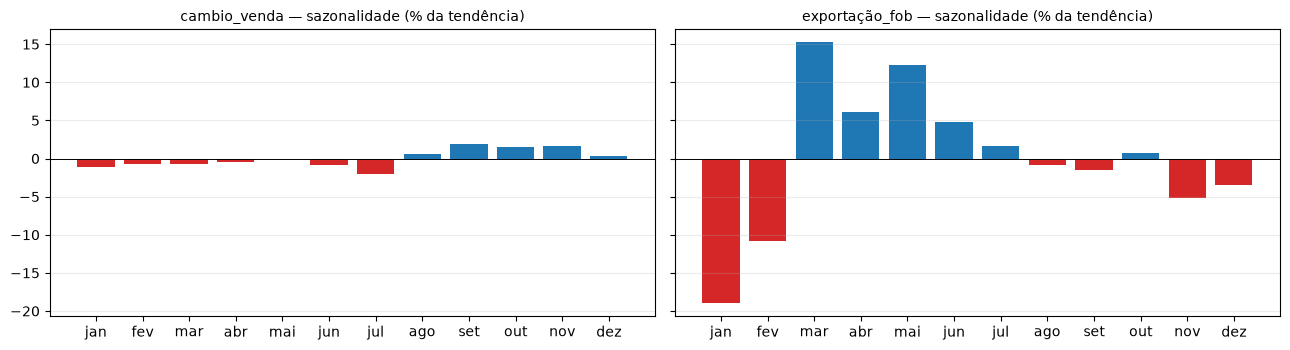

- `exportação_fob`: pico em **mar** (15,2% acima da tendência) e vale em **jan** (-18,9%); amplitude entre o maior e o menor mês: 34,2 pontos percentuais.
- `cambio_venda`: maior desvio sazonal de 2,1% (mês **jul**); amplitude entre o maior e o menor mês: 4,0 pontos percentuais.

In [6]:
def sazonal_pct(c):
    m = escolhido[c]
    r = decomp[(c, m)]
    s12 = r.seasonal.iloc[:12]
    if m == 'multiplicative':
        pct = (s12 - 1) * 100
    else:
        pct = s12 / r.trend.mean() * 100
    pct.index = MESES
    return pct

pct = pd.DataFrame({c: sazonal_pct(c) for c in series})

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, c in zip(axes, series):
    ax.bar(pct.index, pct[c], color=['tab:red' if v < 0 else 'tab:blue' for v in pct[c]])
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set_title(f'{c} — sazonalidade (% da tendência)', fontsize=10)
    ax.grid(alpha=0.25, axis='y')
plt.tight_layout()
plt.show()

exp = pct['exportação_fob']
cam = pct['cambio_venda']
display(Markdown(
    f"- `exportação_fob`: pico em **{exp.idxmax()}** ({fmt(exp.max(), 1)}% acima da tendência) e vale em **{exp.idxmin()}** ({fmt(exp.min(), 1)}%); "
    f"amplitude entre o maior e o menor mês: {fmt(exp.max() - exp.min(), 1)} pontos percentuais.\n"
    f"- `cambio_venda`: maior desvio sazonal de {fmt(cam.abs().max(), 1)}% (mês **{cam.abs().idxmax()}**); amplitude entre o maior e o menor mês: {fmt(cam.max() - cam.min(), 1)} pontos percentuais."
))

## 5. O choque cambial de 2020: tendência ou resíduo?

Ideia levantada na conversa sobre o passo 6: se o choque de 2020 aparecesse como um pico **isolado no resíduo** (nem na tendência, nem na sazonalidade), isso o caracterizaria como evento pontual. Se ele aparecer **na tendência**, é mudança de patamar.

Como a tendência aqui é uma média móvel de 12 meses, ela suaviza qualquer salto brusco: parte do salto vai para a tendência, o resto fica no resíduo, nos meses em volta do salto. A janela abaixo compara dezembro/2019 com o pico do primeiro semestre de 2020.

Os 5 maiores resíduos de `cambio_venda` (em % da tendência):

| mês | observado | tendência | resíduo |
|---|---|---|---|
| 2016-01 | 4,04 | 3,70 | 10,6% |
| 2016-02 | 3,98 | 3,68 | 9,2% |
| 2018-08 | 4,14 | 3,74 | 9,8% |
| 2019-12 | 4,03 | 4,48 | -10,4% |
| 2020-04 | 5,43 | 4,98 | 9,4% |

De dez/2019 a **2020-06** (pico da janela), o câmbio observado subiu 1,45 e a **tendência** subiu 0,71, ou seja, a tendência absorveu **49%** da alta; o resto ficou no resíduo.

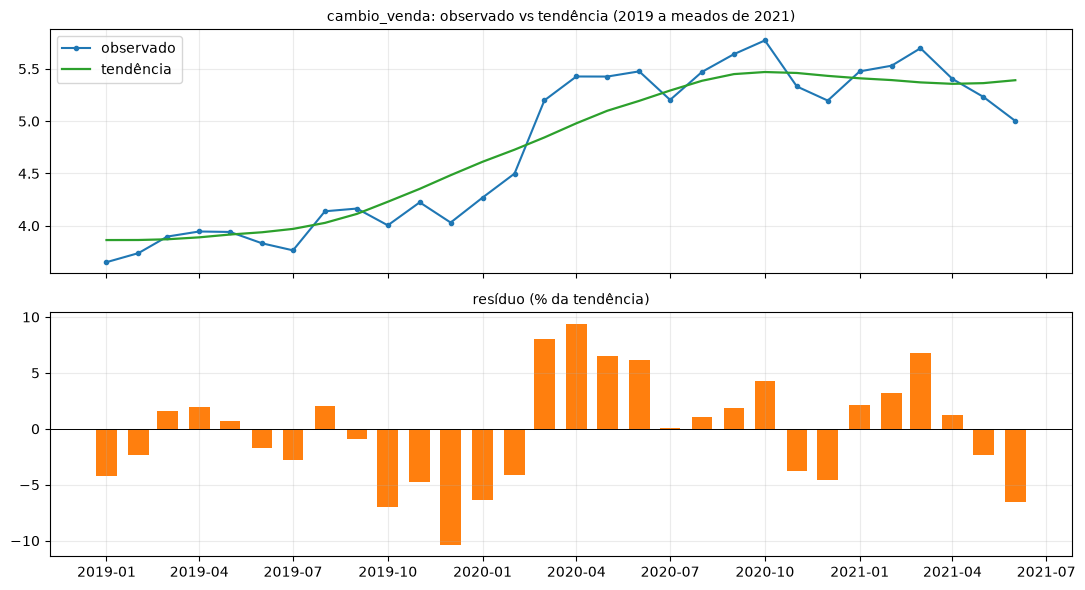

In [7]:
c = 'cambio_venda'
r = decomp[(c, escolhido[c])]

janela = dados.loc['2019-12':'2020-06', c]
dt_pico = janela.idxmax()
d_obs = r.observed.loc[dt_pico] - r.observed.loc['2019-12-01']
d_tend = r.trend.loc[dt_pico] - r.trend.loc['2019-12-01']

res = r.resid.dropna()
rel = res / r.trend.loc[res.index] if escolhido[c] == 'additive' else res - 1
top = rel.abs().sort_values(ascending=False).head(5).index.sort_values()
linhas = [f"| {dt.strftime('%Y-%m')} | {fmt(r.observed.loc[dt])} | {fmt(r.trend.loc[dt])} | {fmt(rel.loc[dt] * 100, 1)}% |" for dt in top]
display(Markdown('Os 5 maiores resíduos de `cambio_venda` (em % da tendência):\n\n| mês | observado | tendência | resíduo |\n|---|---|---|---|\n' + '\n'.join(linhas)))

display(Markdown(
    f"De dez/2019 a **{dt_pico.strftime('%Y-%m')}** (pico da janela), o câmbio observado subiu {fmt(d_obs)} e a **tendência** subiu {fmt(d_tend)}, "
    f"ou seja, a tendência absorveu **{fmt(d_tend / d_obs * 100, 0)}%** da alta; o resto ficou no resíduo."
))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
recorte = slice('2019-01-01', '2021-06-01')
axes[0].plot(r.observed.loc[recorte], color='tab:blue', label='observado', marker='.')
axes[0].plot(r.trend.loc[recorte], color='tab:green', label='tendência', linewidth=1.6)
axes[0].set_title('cambio_venda: observado vs tendência (2019 a meados de 2021)', fontsize=10)
axes[0].legend()
axes[1].bar(rel.loc[recorte].index, rel.loc[recorte] * 100, width=20, color='tab:orange')
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].set_title('resíduo (% da tendência)', fontsize=10)
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Como ler isso:** o choque de 2020 **não** é um pico isolado só no resíduo. Uma parte considerável da alta foi para a **tendência** (mudança de patamar), e o restante aparece como resíduo nos meses em torno do salto. Ou seja, a decomposição não sustenta a ideia de "evento pontual sem efeito duradouro": o câmbio passou para um patamar mais alto, coerente com o que os notebooks 04 e 07 já mostravam (série com choques que se acumulam, sem reversão). Isso responde **o que** aconteceu com o câmbio em 2020; o **porquê** continua na lista de perguntas para a fase de contexto.

**Limitação importante:** como a tendência é uma média móvel, ela "espalha" um salto brusco por vários meses. A divisão exata entre tendência e resíduo em torno de 2020 depende dessa escolha metodológica (janela de 12 meses); o número acima é indicativo, não uma medida precisa.

## 6. Limitações do método (para o relatório)

- **Sazonalidade fixa:** a decomposição clássica assume que o padrão sazonal é **idêntico em todos os anos**. Se o calendário de safra mudar ao longo de 2015–2025, isso fica no resíduo.
- **Perde as pontas:** tendência e resíduo ficam indefinidos nos 6 primeiros e 6 últimos meses, então a análise dos resíduos usa 120 dos 132 meses.
- **Sensível a choques:** um choque como o de 2020 no câmbio influencia a tendência dos meses vizinhos (ver seção 5).
- **Resíduo do câmbio não é ruído puro:** no gráfico da seção 2 o resíduo de `cambio_venda` fica vários meses seguidos acima ou abaixo de zero, ou seja, ainda tem estrutura (autocorrelação) que a média móvel não capturou. Isso é esperado numa série de câmbio, que tem movimentos lentos e persistentes.
- **Alternativa:** a decomposição STL (`statsmodels.tsa.seasonal.STL`) permite sazonalidade que varia no tempo e é mais robusta a pontos atípicos; pode ser usada como checagem se o grupo achar necessário.

## Resumo do passo 6

In [8]:
nome = {'additive': 'aditivo', 'multiplicative': 'multiplicativo'}
texto = f"- Decomposição clássica (período 12) de `cambio_venda` e `exportação_fob` sobre o painel completo (132 meses).\n"
texto += f"- Modelo escolhido pela regra da seção 1: `cambio_venda` → **{nome[escolhido['cambio_venda']]}**; `exportação_fob` → **{nome[escolhido['exportação_fob']]}**.\n"
texto += (f"- Sazonalidade: `exportação_fob` {rotulo(fs['exportação_fob']['sazonalidade'])} ({fmt(fs['exportação_fob']['sazonalidade'])}), "
          f"`cambio_venda` {rotulo(fs['cambio_venda']['sazonalidade'])} ({fmt(fs['cambio_venda']['sazonalidade'])}). "
          f"Pico sazonal das exportações em {exp.idxmax()} e vale em {exp.idxmin()}.\n")
texto += (f"- Separação entre efeito sazonal e efeito cambial: a sazonalidade do câmbio é {rotulo(fs['cambio_venda']['sazonalidade'])}, "
          "então o padrão anual das exportações não vem do câmbio. Se o câmbio afeta as exportações, isso deve aparecer na tendência ou nos movimentos irregulares, não no calendário anual (a testar nos próximos passos).\n")
texto += (f"- Choque de 2020 no câmbio: a tendência absorveu {fmt(d_tend / d_obs * 100, 0)}% da alta entre dez/2019 e {dt_pico.strftime('%Y-%m')}; "
          "não é um pico isolado só no resíduo (interpretação sujeita à suavização da média móvel).\n")
display(Markdown(texto))

- Decomposição clássica (período 12) de `cambio_venda` e `exportação_fob` sobre o painel completo (132 meses).
- Modelo escolhido pela regra da seção 1: `cambio_venda` → **aditivo**; `exportação_fob` → **multiplicativo**.
- Sazonalidade: `exportação_fob` moderada (0,57), `cambio_venda` fraca (0,08). Pico sazonal das exportações em mar e vale em jan.
- Separação entre efeito sazonal e efeito cambial: a sazonalidade do câmbio é fraca, então o padrão anual das exportações não vem do câmbio. Se o câmbio afeta as exportações, isso deve aparecer na tendência ou nos movimentos irregulares, não no calendário anual (a testar nos próximos passos).
- Choque de 2020 no câmbio: a tendência absorveu 49% da alta entre dez/2019 e 2020-06; não é um pico isolado só no resíduo (interpretação sujeita à suavização da média móvel).


**Fecha os 6 passos do roteiro de EDA.** Pendências que a EDA deixou para as próximas etapas:

- **Refazer a correlação (passo 4) em primeira diferença** para as séries I(1) identificadas no `07_estacionariedade.ipynb`, já que a matriz do `06` foi calculada sobre níveis.
- **Decidir como `credito_total` entra** nas análises (nível, Δ ou nível com indicadora do degrau de ago/2019), que depende da pergunta 2 da seção "Perguntas em aberto" do roteiro.
- **Planejar a fase de contexto**, com critérios metodológicos de seleção de fontes.